# Fine-Tuning XLS-R for AI Voice Deepfake Detection (CAC) — English

**What this notebook does, end to end**
1. Checks the GPU and picks batch size / precision automatically.
2. Downloads the base model **`facebook/wav2vec2-xls-r-300m`** (the original, un-fine-tuned XLS-R) and the English part of **MLAAD-tiny** (AI-generated speech from many TTS systems + real M-AILABS audiobook speech).
3. Preprocesses audio (16 kHz, silence trimmed, cached to Google Drive so you only do it once).
4. Trains a real-vs-fake classifier with **phone-call augmentation** (8 kHz telephone band, G.711 μ-law like Twilio, optional Opus codec, packet loss, noise).
5. Evaluates on **TTS systems the model never saw during training** (the honest test), on clean and phone-quality audio.
6. Measures latency, then saves the model, threshold, and a standalone `inference.py` to Drive.

**How to run**
1. `Runtime → Change runtime type → GPU` (T4, L4, or A100 all work; settings adapt automatically).
2. `Runtime → Run all`. Approve the Google Drive popup when it appears (cell 2).
3. If the runtime disconnects, just **Run all** again: data is cached on Drive and training resumes from the last saved epoch.

**Tip to save GPU credits:** cells 1–6 (download + preprocessing) don't need a GPU. Run them once on a **CPU runtime** (Runtime → Change runtime type → CPU); the cache is saved to Drive and reused later. Then switch to a GPU runtime and Run all: the download/preprocess cells are skipped automatically and training starts right away. Preprocessing now streams to disk, so a standard-RAM runtime is enough (no High-RAM needed).

**License note:** MLAAD is CC BY-NC 4.0 (non-commercial use only). That's fine for a CAC entry, but don't ship this model in a paid product without checking the license.

## 1. Configuration — the only cell you might want to edit

In [ ]:
CFG = dict(
    # ---- model ----
    BASE_MODEL   = "facebook/wav2vec2-xls-r-300m",  # original pre-trained XLS-R (300M params)
    KEEP_LAYERS  = 12,      # use the first 12 of 24 transformer layers -> roughly 2x faster inference.
                            # Set to 24 for the full model if accuracy matters more than speed.
    # ---- audio ----
    SR           = 16000,
    TRAIN_SEC    = 4.0,     # window length the model scores (live calls are scored in 4 s windows)
    MAX_STORE_SEC= 8.0,     # max seconds kept per clip in the cache
    MIN_SEC      = 1.0,     # clips shorter than this (after silence trimming) are dropped
    # ---- training ----
    EPOCHS       = 6,
    PATIENCE     = 2,       # early stopping: epochs without val EER improvement
    LR_BACKBONE  = 1e-5,
    LR_HEAD      = 1e-3,
    WEIGHT_DECAY = 1e-4,
    WARMUP_FRAC  = 0.05,
    GRAD_CLIP    = 1.0,
    # ---- augmentation ----
    PHONE_AUG_P  = 0.8,     # fraction of training clips passed through the simulated phone channel
    CODEC_P      = 0.10,    # within the phone channel, chance of an extra Opus encode/decode (needs ffmpeg)
    # ---- splits (by TTS system, so test systems are never seen in training) ----
    TEST_SYSTEM_FRAC = 0.15,
    VAL_SYSTEM_FRAC  = 0.10,
    SEED         = 42,
    # ---- optional: more English fakes from the full (gated) MLAAD dataset ----
    USE_FULL_MLAAD          = True,  # needs a Hugging Face token (Colab secret HF_TOKEN) + accepting MLAAD terms on HF
    EXTRA_FAKES_PER_SYSTEM  = 150,
    DOWNLOAD_WORKERS        = 8,     # parallel downloads for the extra fakes (lower it if you see many failures)
    # ---- storage ----
    DRIVE_DIR    = "/content/drive/MyDrive/CAC_deepfake_detector",
    LOCAL_DIR    = "/content/work",
    # ---- quick end-to-end check (tiny data, a few steps). Leave False for real training. ----
    SMOKE_TEST   = False,
)
print(CFG)

{'BASE_MODEL': 'facebook/wav2vec2-xls-r-300m', 'KEEP_LAYERS': 12, 'SR': 16000, 'TRAIN_SEC': 4.0, 'MAX_STORE_SEC': 8.0, 'MIN_SEC': 1.0, 'EPOCHS': 6, 'PATIENCE': 2, 'LR_BACKBONE': 1e-05, 'LR_HEAD': 0.001, 'WEIGHT_DECAY': 0.0001, 'WARMUP_FRAC': 0.05, 'GRAD_CLIP': 1.0, 'PHONE_AUG_P': 0.8, 'CODEC_P': 0.1, 'TEST_SYSTEM_FRAC': 0.15, 'VAL_SYSTEM_FRAC': 0.1, 'SEED': 42, 'USE_FULL_MLAAD': True, 'EXTRA_FAKES_PER_SYSTEM': 150, 'DOWNLOAD_WORKERS': 8, 'DRIVE_DIR': '/content/drive/MyDrive/CAC_deepfake_detector', 'LOCAL_DIR': '/content/work', 'SMOKE_TEST': False}


## 2. GPU check, Drive, and automatic batch/precision settings

In [ ]:
import os, sys, subprocess, torch

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
else:
    CFG["DRIVE_DIR"] = os.path.abspath("drive_out"); CFG["LOCAL_DIR"] = os.path.abspath("work")
os.makedirs(CFG["DRIVE_DIR"], exist_ok=True); os.makedirs(CFG["LOCAL_DIR"], exist_ok=True)

if torch.cuda.is_available():
    DEVICE = "cuda"
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / 1e9
    # bf16 is native only on compute capability >= 8 (A100, L4, H100). A T4 reports 'supported' through slow
    # emulation, so ask for real support and fall back to fp16 (+ GradScaler) there.
    try:    USE_BF16 = torch.cuda.is_bf16_supported(including_emulation=False)
    except TypeError: USE_BF16 = torch.cuda.get_device_capability()[0] >= 8   # older torch without the flag
    AMP_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
    if   gpu_mem >= 70: BATCH, ACCUM = 32, 1
    elif gpu_mem >= 35: BATCH, ACCUM = 24, 1
    elif gpu_mem >= 20: BATCH, ACCUM = 16, 2
    else:               BATCH, ACCUM = 8, 4
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
    print(f"GPU: {gpu_name} ({gpu_mem:.0f} GB) | precision: {'bf16' if USE_BF16 else 'fp16'} | batch {BATCH} x accum {ACCUM} = {BATCH*ACCUM}")
else:
    DEVICE, AMP_DTYPE, BATCH, ACCUM, gpu_mem = "cpu", None, 2, 1, 0
    print("⚠️  No GPU detected. Data download/preprocessing (cells 3-6) is fine on CPU, "
          "but switch to a GPU runtime before training (Runtime -> Change runtime type).")
    if not CFG["SMOKE_TEST"]:
        print("    Training cells will refuse to run on CPU unless SMOKE_TEST=True.")

NUM_WORKERS = min(4, os.cpu_count() or 2)
print("CPU workers:", NUM_WORKERS)

Mounted at /content/drive
Sat Oct 10 23:23:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   37C    P8             14W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

## 3. Install / check packages
Colab already has torch and transformers. This only adds small extras and does **not** reinstall torch (the old `torchaudio ... cu113` line was removed because it can break Colab's CUDA build).

In [ ]:
%pip install -q soundfile scikit-learn matplotlib tqdm   # no -U: upgrading pandas/pyarrow breaks Colab's pinned packages
import transformers, huggingface_hub, numpy as np
print("torch", torch.__version__, "| transformers", transformers.__version__, "| huggingface_hub", huggingface_hub.__version__, "| numpy", np.__version__)
HAS_FFMPEG = subprocess.run("ffmpeg -hide_banner -encoders 2>/dev/null | grep -q libopus", shell=True).returncode == 0
print("ffmpeg with libopus:", HAS_FFMPEG)

torch 2.11.0+cu130 | transformers 5.18.0 | huggingface_hub 1.33.0 | numpy 2.1.3
ffmpeg with libopus: True


## 4. Imports and seeds

In [ ]:
import re, io, json, math, time, glob, random, shutil, tempfile
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, soundfile as sf
from scipy.signal import resample_poly, butter, sosfilt
from tqdm.auto import tqdm
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import roc_curve, roc_auc_score
from huggingface_hub import HfApi, snapshot_download, hf_hub_download

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["SEED"])

SR = CFG["SR"]; WIN = int(CFG["TRAIN_SEC"] * SR)
CACHE_DIR = Path(CFG["DRIVE_DIR"]) / ("cache_smoke" if CFG["SMOKE_TEST"] else "cache_en")
CKPT_DIR  = Path(CFG["DRIVE_DIR"]) / ("ckpt_smoke"  if CFG["SMOKE_TEST"] else "ckpt_en")
CACHE_DIR.mkdir(parents=True, exist_ok=True); CKPT_DIR.mkdir(parents=True, exist_ok=True)

def get_hf_token():
    tok = os.environ.get("HF_TOKEN")
    if tok: return tok
    try:
        from google.colab import userdata
        return userdata.get("HF_TOKEN")
    except Exception:
        return None

## 5. Download the original model and the English data
Skipped automatically if the preprocessed cache already exists on Drive.

**If this cell is slow or you need to stop it:** press Stop and run it again. Files already downloaded are kept and skipped (they live on the Colab VM disk, so they survive Stop but not a runtime reset). The extra fakes show ONE progress bar and a failure count; a few failures are fine (those files are simply skipped).

In [ ]:
CACHE_READY = (CACHE_DIR / "manifest.csv").exists() and (CACHE_DIR / "audio_int16.npy").exists()
RAW = Path(CFG["LOCAL_DIR"]) / "mlaad_tiny"
EXTRA = Path(CFG["LOCAL_DIR"]) / "mlaad_full"

import contextlib
from concurrent.futures import as_completed

@contextlib.contextmanager
def robust_quiet_hf(download_timeout=60):
    """For the many-small-files download only: no per-file progress bars (thousands of them can freeze the Colab page),
    plain HTTP instead of hf-xet, and a longer network timeout than the 10 s default. Settings are restored afterwards."""
    from huggingface_hub import constants as hfc
    from huggingface_hub.utils import disable_progress_bars, enable_progress_bars
    old = (hfc.HF_HUB_DISABLE_XET, hfc.HF_HUB_DOWNLOAD_TIMEOUT)
    hfc.HF_HUB_DISABLE_XET, hfc.HF_HUB_DOWNLOAD_TIMEOUT = True, download_timeout
    disable_progress_bars()
    try:
        yield
    finally:
        hfc.HF_HUB_DISABLE_XET, hfc.HF_HUB_DOWNLOAD_TIMEOUT = old
        enable_progress_bars()

def download_files(repo_id, files, dest, token=None, workers=8, retries=4):
    """Resumable parallel download of individual dataset files with ONE progress bar.
    Skips files already on disk, retries with backoff, never hangs the whole cell on one bad file.
    Press Stop to interrupt; run again to resume. Returns a list of (file, error) for files that still failed."""
    dest = Path(dest); counts = dict(ok=0, had=0, fail=0); failed = []
    def one(f):
        p = dest / f
        if p.exists() and p.stat().st_size > 0: return f, "had", None
        err = None
        for attempt in range(retries):
            try:
                hf_hub_download(repo_id, f, repo_type="dataset", local_dir=str(dest), token=token, etag_timeout=30)
                return f, "ok", None
            except Exception as e:
                err = repr(e)[:200]
                time.sleep(30 if "429" in err else 2 ** attempt)
        return f, "fail", err
    ex = ThreadPoolExecutor(workers)
    try:
        with robust_quiet_hf(), tqdm(total=len(files), desc="downloading", mininterval=2) as bar:
            futs = [ex.submit(one, f) for f in files]
            for fut in as_completed(futs):
                f, status, err = fut.result(); counts[status] += 1
                if status == "fail": failed.append((f, err))
                bar.update(1); bar.set_postfix(**counts)
    except BaseException:
        ex.shutdown(wait=False, cancel_futures=True)   # lets the Stop button work right away
        raise
    ex.shutdown()
    return failed

# Original model (cached by Hugging Face; ~1.2 GB). Downloading now so training starts instantly later.
snapshot_download(CFG["BASE_MODEL"], allow_patterns=["*.json", "*.bin", "*.safetensors", "*.txt"])
print("Base model ready:", CFG["BASE_MODEL"])

if CACHE_READY:
    print("Preprocessed cache found on Drive -> skipping data download.")
else:
    api = HfApi()
    files = api.list_repo_files("mueller91/MLAAD-tiny", repo_type="dataset")
    fake_en = [f for f in files if f.startswith("fake/en/") and f.endswith(".wav")]
    real_en = [f for f in files if f.startswith("original/en/") and f.endswith(".wav")]
    print(f"MLAAD-tiny English: {len(fake_en)} fake clips, {len(real_en)} real clips, "
          f"{len({f.split('/')[2] for f in fake_en})} TTS systems")
    if CFG["SMOKE_TEST"]:
        rng = random.Random(0)
        by_sys = {}
        for f in fake_en: by_sys.setdefault(f.split("/")[2], []).append(f)
        pick = [f for s in sorted(by_sys)[:20] for f in by_sys[s][:5]] + rng.sample(real_en, 100)
        patterns = [glob.escape(p) for p in pick]
    else:
        patterns = ["fake/en/*", "original/en/*"]
    snapshot_download("mueller91/MLAAD-tiny", repo_type="dataset", local_dir=str(RAW),
                      allow_patterns=patterns + ["README.md", "LICENSE", "original/LICENSE"], max_workers=16)
    print("Downloaded to", RAW)

    # Optional: extra English fakes from the full gated MLAAD (more TTS variety -> better generalization)
    if CFG["USE_FULL_MLAAD"] and not CFG["SMOKE_TEST"]:
        tok = get_hf_token()
        if not tok:
            print("⚠️ USE_FULL_MLAAD=True but no HF_TOKEN found (add it under the 🔑 Secrets tab and turn on Notebook access). Skipping.")
        else:
            try:
                full = api.list_repo_files("mueller91/MLAAD", repo_type="dataset", token=tok)
            except Exception as e:
                full = None
                print("⚠️ Could not access full MLAAD (did you accept its terms on huggingface.co?):", e)
            if full is not None:
                tiny_set = set(fake_en)
                by_sys = {}
                for f in full:
                    if f.startswith("fake/en/") and f.endswith(".wav") and f not in tiny_set:
                        by_sys.setdefault(f.split("/")[2], []).append(f)
                rng = random.Random(CFG["SEED"])
                want = [f for s in sorted(by_sys) for f in rng.sample(by_sys[s], min(len(by_sys[s]), CFG["EXTRA_FAKES_PER_SYSTEM"]))]
                have = sum((EXTRA / f).exists() for f in want)
                print(f"Full MLAAD: {len(want)} extra English fakes from {len(by_sys)} systems ({have} already on disk)")
                failed = download_files("mueller91/MLAAD", want, EXTRA, token=tok, workers=CFG["DOWNLOAD_WORKERS"])
                print(f"done; {len(failed)} failures")
                if failed:
                    EXTRA.mkdir(parents=True, exist_ok=True)
                    (EXTRA / "failed.txt").write_text("\n".join(f"{f}\t{e}" for f, e in failed))
                    print("Run this cell again to retry just those. Files that still fail are skipped, which is harmless "
                          "unless it is a large share (details in", EXTRA / "failed.txt", ")")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Base model ready: facebook/wav2vec2-xls-r-300m
Preprocessed cache found on Drive -> skipping data download.


## 6. Preprocess: resample, trim silence, split by TTS system, cache to Drive
Silence trimming matters: M-AILABS real clips have ~0.5 s of padded silence, and a model can 'cheat' by learning silence length instead of voice artifacts.

In [ ]:
def load_audio(path, sr=SR):
    x, s = sf.read(path, dtype="float32", always_2d=True)
    x = x.mean(axis=1)
    if s != sr:
        g = math.gcd(int(s), sr); x = resample_poly(x, sr // g, int(s) // g).astype(np.float32)
    return x

def trim_silence(x, sr=SR, top_db=40.0, frame=0.02):
    n = int(sr * frame)
    if len(x) < n * 2: return x
    k = len(x) // n
    e = 10 * np.log10(np.mean(x[: k * n].reshape(k, n) ** 2, axis=1) + 1e-12)
    keep = np.where(e > e.max() - top_db)[0]
    if len(keep) == 0: return x
    return x[keep[0] * n : (keep[-1] + 1) * n]

def book_group(stem):
    s = re.sub(r"_f\d+$", "", stem)
    return re.sub(r"_\d+(?=_|$)", "", s)

def system_split(systems, seed):
    systems = sorted(systems); rng = random.Random(seed); rng.shuffle(systems)
    n_te = max(1, round(len(systems) * CFG["TEST_SYSTEM_FRAC"])); n_va = max(1, round(len(systems) * CFG["VAL_SYSTEM_FRAC"]))
    return set(systems[:n_te]), set(systems[n_te:n_te + n_va])

if CACHE_READY:
    manifest = pd.read_csv(CACHE_DIR / "manifest.csv")
else:
    items = []
    for root in [RAW, Path(CFG["LOCAL_DIR"]) / "mlaad_full"]:
        for p in (root / "fake" / "en").glob("*/*.wav"):
            items.append(dict(path=str(p), label=1, system=p.parent.name, group=p.parent.name))
    for p in (RAW / "original" / "en").rglob("*.wav"):
        items.append(dict(path=str(p), label=0, system="bonafide", group=book_group(p.stem)))
    print(f"{len(items)} files found ({sum(i['label'] for i in items)} fake)")

    def proc(it):
        try:
            x = trim_silence(load_audio(it["path"]))
            if len(x) < CFG["MIN_SEC"] * SR: return None
            x = x[: int(CFG["MAX_STORE_SEC"] * SR)]
            peak = np.abs(x).max()
            if peak < 1e-4: return None
            x = x / peak * 0.9
            return (x * 32767).astype(np.int16)
        except Exception as e:
            return None

    # Stream each processed clip straight to disk instead of holding every clip in RAM. (The old version kept the whole
    # list AND a concatenated copy, which could pass a standard Colab runtime's RAM.)
    RAW_BLOB = Path(CFG["LOCAL_DIR"]) / "audio_int16.raw"
    LOCAL_BLOB = Path(CFG["LOCAL_DIR"]) / "audio_int16.npy"
    kept_items, lengths, CHUNK = [], [], 256
    with open(RAW_BLOB, "wb") as fh, ThreadPoolExecutor(NUM_WORKERS * 2) as ex, \
         tqdm(total=len(items), desc="preprocess") as bar:
        for s in range(0, len(items), CHUNK):
            chunk = items[s:s + CHUNK]
            for it, a in zip(chunk, ex.map(proc, chunk)):
                if a is not None:
                    fh.write(a.tobytes()); kept_items.append(it); lengths.append(len(a))
            bar.update(len(chunk))
    print(f"kept {len(kept_items)} / {len(items)} clips")
    if not kept_items:
        raise RuntimeError("No usable audio was found - check the download step above.")
    lengths = np.array(lengths, dtype=np.int64); offsets = np.concatenate([[0], np.cumsum(lengths)[:-1]])
    n_samples = int(lengths.sum())
    # Convert the raw file into a standard .npy (copied in blocks) so everything downstream is unchanged.
    out = np.lib.format.open_memmap(LOCAL_BLOB, mode="w+", dtype=np.int16, shape=(n_samples,))
    raw = np.memmap(RAW_BLOB, dtype=np.int16, mode="r")
    for s in range(0, n_samples, 1 << 26):
        out[s:s + (1 << 26)] = raw[s:s + (1 << 26)]
    out.flush(); del out, raw; RAW_BLOB.unlink()
    manifest = pd.DataFrame(kept_items); manifest["offset"] = offsets; manifest["length"] = lengths
    manifest["path"] = manifest["path"].map(lambda p: os.path.relpath(p, CFG["LOCAL_DIR"]))

    # --- splits ---
    fake_sys = sorted(manifest.loc[manifest.label == 1, "system"].unique())
    test_sys, val_sys = system_split(fake_sys, CFG["SEED"])
    rng = np.random.default_rng(CFG["SEED"])
    split = np.array(["train"] * len(manifest), dtype=object)
    f = manifest.label == 1
    split[(f & manifest.system.isin(test_sys)).values] = "test"
    split[(f & manifest.system.isin(val_sys)).values] = "val"
    seen = (f & ~manifest.system.isin(test_sys | val_sys)).values
    split[seen & (rng.random(len(manifest)) < 0.08)] = "val"          # a few held-out files from seen systems
    groups = sorted(manifest.loc[~f, "group"].unique()); random.Random(CFG["SEED"]).shuffle(groups)
    n_te, n_va = round(len(groups) * 0.15), round(len(groups) * 0.10)
    g_te, g_va = set(groups[:n_te]), set(groups[n_te:n_te + n_va])
    split[(~f & manifest.group.isin(g_te)).values] = "test"
    split[(~f & manifest.group.isin(g_va)).values] = "val"
    manifest["split"] = split

    manifest.to_csv(Path(CFG["LOCAL_DIR"]) / "manifest.csv", index=False)
    shutil.copy(LOCAL_BLOB, CACHE_DIR / "audio_int16.npy")
    shutil.copy(Path(CFG["LOCAL_DIR"]) / "manifest.csv", CACHE_DIR / "manifest.csv")
    print("Cache saved to Drive:", CACHE_DIR, f"({LOCAL_BLOB.stat().st_size/1e9:.2f} GB)")

# Load the cache from local disk (faster than reading from Drive during training)
local_blob = Path(CFG["LOCAL_DIR"]) / "audio_int16.npy"
if not local_blob.exists():
    shutil.copy(CACHE_DIR / "audio_int16.npy", local_blob)
BLOB = np.load(local_blob, mmap_mode="r")

print(manifest.groupby(["split", "label"]).size().unstack().rename(columns={0: "real", 1: "fake"}))
print("\nUnseen TEST TTS systems:", sorted(manifest.query("split=='test' and label==1").system.unique()))
print("Unseen VAL TTS systems: ", sorted(set(manifest.query("split=='val' and label==1").system) - set(manifest.query("split=='train'").system)))
print(f"Total audio: {manifest.length.sum()/SR/3600:.1f} h")

label  real   fake
split             
test    753   4027
train  4337  19370
val     935   4265

Unseen TEST TTS systems: ['Inworld-TTS-2', 'Llasa-1B', 'Llasa-1B-Multilingual', 'Llasa-8B', 'LongCat-AudioDiT', 'MegaTTS3', 'MisoTTS', 'NeuTTS-Nano', 'OpenAI TTS-1 HD', 'OpenVoiceV2', 'Qwen2.5-Omni', 'Resemble.ai (April 12th, 2025)', 'Spark-TTS-0.5B', 'VoXtream2', 'facebook_mms-tts-eng', 'parler_tts_large_v1', 'tts_models_en_ljspeech_glow-tts', 'tts_models_en_ljspeech_neural_hmm', 'tts_models_en_ljspeech_tacotron2-DCA', 'tts_models_en_ljspeech_vits--neon', 'tts_models_multilingual_multi-dataset_xtts_v1.1']
Unseen VAL TTS systems:  ['Audio8-TTS-Preview-0.6b', 'GPA-v1.5', 'Kitten-TTS-Nano-0.1', 'MingTTS', 'Qwen3-TTS-12Hz-1.7B-Base', 'Smallest-Lightning-v3.1', 'Voxtral', 'dots.tts-base', 'f5-tts', 'sesame_csm', 'suno_bark', 'suno_bark-small', 'tts_models_en_ljspeech_fast_pitch', 'tts_models_en_ljspeech_tacotron2-DDC']
Total audio: 56.1 h


## 7. Phone-call channel simulation
Applied to **both** real and fake clips with the same probability, so the model can't use 'sounds like a phone' as a shortcut. Twilio Media Streams deliver 8 kHz μ-law audio, which is what this mimics.

In [ ]:
_SOS_PHONE = butter(4, [300, 3400], btype="bandpass", fs=8000, output="sos")

def mulaw_roundtrip(x, mu=255):
    x = np.clip(x, -1, 1)
    y = np.sign(x) * np.log1p(mu * np.abs(x)) / np.log1p(mu)
    q = np.round((y + 1) / 2 * mu) / mu * 2 - 1                    # 8-bit quantization
    return (np.sign(q) * ((1 + mu) ** np.abs(q) - 1) / mu).astype(np.float32)

def opus_roundtrip(x8k, bitrate):
    with tempfile.TemporaryDirectory() as d:
        a, b, c = f"{d}/a.wav", f"{d}/b.ogg", f"{d}/c.wav"
        sf.write(a, x8k, 8000)
        r = subprocess.run(f"ffmpeg -loglevel quiet -y -i {a} -c:a libopus -b:a {bitrate} {b} && "
                           f"ffmpeg -loglevel quiet -y -i {b} -ar 8000 -ac 1 {c}", shell=True)
        if r.returncode != 0: return x8k
        y, _ = sf.read(c, dtype="float32")
        y = y[: len(x8k)]
        return np.pad(y, (0, len(x8k) - len(y))) if len(y) < len(x8k) else y

def phone_channel(x, rng):
    """x: float32 16 kHz -> same length, float32 16 kHz, degraded like a phone call."""
    n = len(x)
    x = x * 10 ** (rng.uniform(-12, 3) / 20)                              # level change
    y = resample_poly(x, 1, 2).astype(np.float32)                         # 16k -> 8k
    if rng.random() < 0.8: y = sosfilt(_SOS_PHONE, y).astype(np.float32)  # telephone band 300-3400 Hz
    if HAS_FFMPEG and rng.random() < CFG["CODEC_P"]:
        y = opus_roundtrip(y, rng.choice(["8k", "12k", "16k"]))
    if rng.random() < 0.85: y = mulaw_roundtrip(y)                        # G.711 mu-law (Twilio)
    if rng.random() < 0.3:                                                # packet loss: drop 20 ms frames
        fl = 160; k = len(y) // fl
        drop = np.repeat(rng.random(k) < 0.02, fl)
        y[: k * fl][drop] = 0
    y = resample_poly(y, 2, 1).astype(np.float32)[:n]                      # back to 16k
    if len(y) < n: y = np.pad(y, (0, n - len(y)))
    if rng.random() < 0.6:                                                # background noise
        snr = rng.uniform(10, 40); p = np.mean(y ** 2) + 1e-9
        noise = rng.standard_normal(n).astype(np.float32)
        if rng.random() < 0.5: noise = np.cumsum(noise); noise -= noise.mean(); noise /= noise.std() + 1e-9  # brown-ish
        y = y + noise * np.sqrt(p / 10 ** (snr / 10))
    return np.clip(y, -1, 1).astype(np.float32)

# quick sanity check
_t = np.random.default_rng(0).standard_normal(WIN).astype(np.float32) * 0.1
assert phone_channel(_t, np.random.default_rng(1)).shape == (WIN,)
print("phone channel OK")

phone channel OK


## 8. Dataset and loaders

In [ ]:
def fit_window(x, rng=None):
    """Random crop (train) or center crop (eval) to WIN samples; short clips are tiled, not zero-padded."""
    if len(x) < WIN:
        x = np.tile(x, int(np.ceil(WIN / len(x))))[:WIN] if len(x) else np.zeros(WIN, np.float32)
    elif len(x) > WIN:
        s = rng.integers(0, len(x) - WIN + 1) if rng is not None else (len(x) - WIN) // 2
        x = x[s:s + WIN]
    return x

def normalize(x):
    return ((x - x.mean()) / (x.std() + 1e-7)).astype(np.float32)

class AudioDS(Dataset):
    def __init__(self, df, train=False, phone=False, seed=0):
        self.df = df.reset_index(drop=True); self.train, self.phone, self.seed = train, phone, seed
        self.off, self.len, self.lab = (self.df[c].to_numpy() for c in ["offset", "length", "label"])
        self.rng = np.random.default_rng(seed)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        o, n = int(self.off[i]), int(self.len[i])
        x = np.asarray(BLOB[o:o + n], dtype=np.float32) / 32768.0
        if self.train:
            rng = self.rng
            x = fit_window(x, rng)
            if rng.random() < CFG["PHONE_AUG_P"]: x = phone_channel(x, rng)
        else:
            x = fit_window(x)
            if self.phone: x = phone_channel(x, np.random.default_rng(self.seed * 100003 + i))  # deterministic
        return torch.from_numpy(normalize(x)), torch.tensor(float(self.lab[i]))

def worker_init(_):
    info = torch.utils.data.get_worker_info()
    info.dataset.rng = np.random.default_rng(torch.initial_seed() % 2**32)

df = manifest.copy()
if CFG["SMOKE_TEST"]:
    df = pd.concat([d.head(40) for _, d in df.groupby(["split", "label"])])
train_df, val_df, test_df = (df[df.split == s] for s in ["train", "val", "test"])

# class-balanced sampling
w = train_df.label.map(1.0 / train_df.label.value_counts()).values
sampler = WeightedRandomSampler(torch.tensor(w, dtype=torch.double), num_samples=len(train_df), replacement=True)
dl_kw = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"), worker_init_fn=worker_init,
             persistent_workers=NUM_WORKERS > 0)
train_dl = DataLoader(AudioDS(train_df, train=True, seed=CFG["SEED"]), batch_size=BATCH, sampler=sampler, drop_last=True, **dl_kw)
val_dl   = DataLoader(AudioDS(val_df, phone=True, seed=1), batch_size=BATCH * 2, **dl_kw)   # validate on phone-quality audio
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)} | steps/epoch {len(train_dl)//ACCUM}")
xb, yb = next(iter(train_dl)); print("batch:", tuple(xb.shape), yb.tolist()[:8])

train 23707 | val 5200 | test 4780 | steps/epoch 740
batch: (16, 64000) [1.0, 1.0, 1.0, 0.0, 1.0, 0.0, 0.0, 1.0]


## 9. Model: XLS-R backbone (first `KEEP_LAYERS` layers) + learned layer weighting + attentive statistics pooling

In [ ]:
from transformers import Wav2Vec2Config, Wav2Vec2Model

class AttnStatsPool(nn.Module):
    def __init__(self, d):
        super().__init__(); self.att = nn.Sequential(nn.Linear(d, 128), nn.Tanh(), nn.Linear(128, 1))
    def forward(self, h):                        # h: (B, T, d)
        a = torch.softmax(self.att(h).float(), dim=1).to(h.dtype)
        mu = (a * h).sum(1)
        sd = torch.sqrt(((a * (h - mu.unsqueeze(1)) ** 2).sum(1)).clamp(min=1e-6))
        return torch.cat([mu, sd], dim=-1)

class DeepfakeDetector(nn.Module):
    def __init__(self, base, keep_layers, pretrained=True):
        super().__init__()
        cfg = Wav2Vec2Config.from_pretrained(base)
        cfg.num_hidden_layers = keep_layers
        cfg.layerdrop = 0.0
        cfg.mask_time_prob = 0.05          # light SpecAugment-style masking during training
        cfg.mask_feature_prob = 0.0
        self.backbone = Wav2Vec2Model.from_pretrained(base, config=cfg) if pretrained else Wav2Vec2Model(cfg)
        for p in self.backbone.feature_extractor.parameters():   # CNN front-end stays frozen (standard, saves memory)
            p.requires_grad = False
        d = cfg.hidden_size
        self.layer_w = nn.Parameter(torch.zeros(keep_layers + 1))
        self.proj = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 256), nn.GELU())
        self.pool = AttnStatsPool(256)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(512, 128), nn.GELU(), nn.Dropout(0.2), nn.Linear(128, 1))
    def forward(self, wav):                          # wav: (B, samples) normalized 16 kHz
        hs = self.backbone(wav, output_hidden_states=True).hidden_states   # tuple of (B, T, d)
        w = torch.softmax(self.layer_w, 0)
        h = sum(w[i] * hs[i] for i in range(len(hs)))
        return self.head(self.pool(self.proj(h))).squeeze(-1)   # logit; sigmoid -> P(fake)

if DEVICE == "cpu" and not CFG["SMOKE_TEST"]:
    raise SystemExit("Stop: switch to a GPU runtime before training (or set SMOKE_TEST=True for a CPU check).")

model = DeepfakeDetector(CFG["BASE_MODEL"], CFG["KEEP_LAYERS"]).to(DEVICE)
if DEVICE == "cuda" and gpu_mem < 20:
    try:
        model.backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        print("gradient checkpointing on (small GPU)")
    except Exception as e:
        print("gradient checkpointing unavailable:", e)
n_par = sum(p.numel() for p in model.parameters()); n_tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"params: {n_par/1e6:.1f}M total, {n_tr/1e6:.1f}M trainable")

Loading weights:   0%|          | 0/230 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                                                                      | Status     |  | 
-------------------------------------------------------------------------+------------+--+-
wav2vec2.encoder.layers.{12...23}.attention.v_proj.weight                | UNEXPECTED |  | 
wav2vec2.encoder.layers.{12...23}.final_layer_norm.weight                | UNEXPECTED |  | 
wav2vec2.encoder.layers.{12...23}.layer_norm.bias                        | UNEXPECTED |  | 
wav2vec2.encoder.layers.{12...23}.final_layer_norm.bias                  | UNEXPECTED |  | 
wav2vec2.encoder.layers.{12...23}.attention.q_proj.weight                | UNEXPECTED |  | 
wav2vec2.encoder.layers.{12...23}.attention.out_proj.bias                | UNEXPECTED |  | 
wav2vec2.encoder.layers.{12...23}.attention.out_proj.weight              | UNEXPECTED |  | 
wav2vec2.encoder.layers.{12...23}.layer_norm.weight                      | UNEXPECTED |  | 
wav2

params: 164.6M total, 160.4M trainable


## 10. Train (auto-resumes from Drive if the runtime disconnected)

In [ ]:
def compute_eer(y, s):
    fpr, tpr, thr = roc_curve(y, s); fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr))
    return float((fpr[i] + fnr[i]) / 2), float(thr[i])

@torch.no_grad()
def predict(dl):
    model.eval(); S, Y = [], []
    for x, y in dl:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=AMP_DTYPE or torch.float16, enabled=AMP_DTYPE is not None):
            S.append(torch.sigmoid(model(x).float()).cpu()); Y.append(y)
    return torch.cat(Y).numpy(), torch.cat(S).numpy()

head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.") and p.requires_grad]
bb_params   = [p for n, p in model.named_parameters() if n.startswith("backbone.") and p.requires_grad]
opt = torch.optim.AdamW([{"params": bb_params, "lr": CFG["LR_BACKBONE"]},
                         {"params": head_params, "lr": CFG["LR_HEAD"]}], weight_decay=CFG["WEIGHT_DECAY"])
steps_per_epoch = max(1, len(train_dl) // ACCUM)
epochs = 1 if CFG["SMOKE_TEST"] else CFG["EPOCHS"]
total_steps = steps_per_epoch * epochs; warm = max(1, int(total_steps * CFG["WARMUP_FRAC"]))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total_steps))))
scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))
loss_fn = nn.BCEWithLogitsLoss()

start_epoch, best_eer, bad_epochs, history = 0, 1.0, 0, []
last_ckpt, best_ckpt = CKPT_DIR / "last.pt", CKPT_DIR / "best.pt"
if last_ckpt.exists():
    ck = torch.load(last_ckpt, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    if ck.get("scaler"): scaler.load_state_dict(ck["scaler"])   # empty when the saving run used bf16 (no scaler)
    start_epoch, best_eer, bad_epochs, history = ck["epoch"] + 1, ck["best_eer"], ck["bad_epochs"], ck["history"]
    print(f"Resumed after epoch {ck['epoch']+1} (best val EER {best_eer:.4f})")

for epoch in range(start_epoch, epochs):
    if bad_epochs >= CFG["PATIENCE"]:
        print("Early stopping."); break
    model.train(); t0 = time.time(); run = 0.0; opt.zero_grad(set_to_none=True)
    pbar = tqdm(enumerate(train_dl), total=len(train_dl), desc=f"epoch {epoch+1}/{epochs}")
    for i, (x, y) in pbar:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast("cuda", dtype=AMP_DTYPE or torch.float16, enabled=AMP_DTYPE is not None):
            loss = loss_fn(model(x).float(), y) / ACCUM
        scaler.scale(loss).backward()
        if (i + 1) % ACCUM == 0:
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["GRAD_CLIP"])
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        run = 0.98 * run + 0.02 * loss.item() * ACCUM if i else loss.item() * ACCUM
        if i % 20 == 0: pbar.set_postfix(loss=f"{run:.4f}", lr=f"{sched.get_last_lr()[0]:.2e}")
        if CFG["SMOKE_TEST"] and i >= 10: break
    yv, sv = predict(val_dl)
    eer, thr = compute_eer(yv, sv); auc = roc_auc_score(yv, sv)
    history.append(dict(epoch=epoch + 1, loss=run, val_eer=eer, val_auc=auc, minutes=(time.time() - t0) / 60))
    print(f"epoch {epoch+1}: train loss {run:.4f} | val EER {eer*100:.2f}% | val AUC {auc:.4f} | {(time.time()-t0)/60:.1f} min")
    if eer < best_eer:
        best_eer, bad_epochs = eer, 0
        torch.save({"model": model.state_dict(), "val_eer": eer, "val_eer_threshold": thr, "cfg": CFG}, best_ckpt)
        print("  ✓ new best saved to Drive")
    else:
        bad_epochs += 1
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                "epoch": epoch, "best_eer": best_eer, "bad_epochs": bad_epochs, "history": history}, last_ckpt)

print(pd.DataFrame(history))

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.27GB            

model.safetensors: downloading bytes:           |  0.00B            

Resumed after epoch 6 (best val EER 0.1081)
   epoch      loss   val_eer   val_auc   minutes
0      1  0.104452  0.169904  0.915036  8.115033
1      2  0.100790  0.139038  0.940671  8.063821
2      3  0.054945  0.121103  0.946059  7.991763
3      4  0.039478  0.108121  0.959138  7.984422
4      5  0.027198  0.113191  0.952281  7.984790
5      6  0.034780  0.111184  0.949092  8.000810


## 11. Evaluate on unseen TTS systems (clean and phone-quality audio)
**EER** = error rate where false alarms equal misses (lower is better). For a scam firewall, false alarms on real family calls matter a lot, so it also reports how many fakes are caught when only 1% / 5% of real calls get flagged.

    test/clean: EER  0.59% | AUC 0.9992 | fakes caught @1% FPR  99.5% | @5% FPR  99.7% | at saved threshold: real flagged 0.0%, fakes caught 89.2%
    test/phone: EER  1.72% | AUC 0.9981 | fakes caught @1% FPR  98.1% | @5% FPR  98.9% | at saved threshold: real flagged 0.0%, fakes caught 79.0%


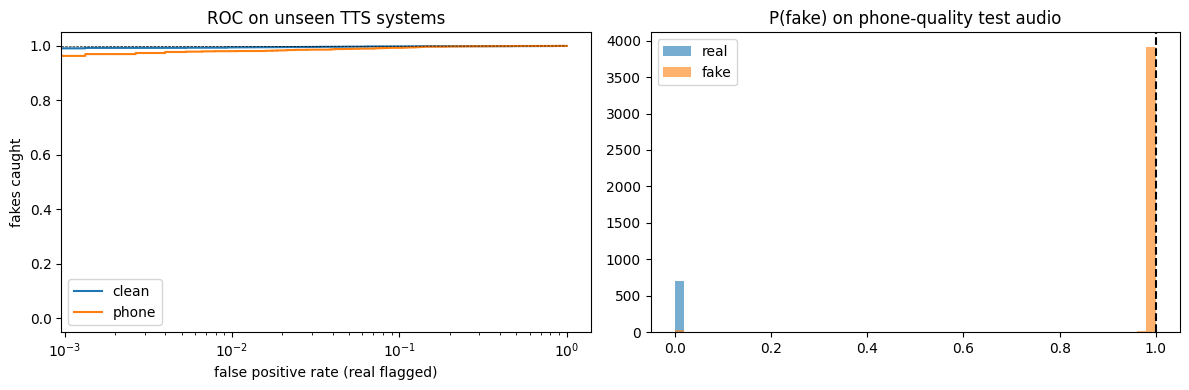


Detection rate per unseen TTS system (phone audio, saved threshold):
 system
LongCat-AudioDiT                                   13.3
Spark-TTS-0.5B                                     53.0
Llasa-8B                                           54.6
MegaTTS3                                           68.3
Qwen2.5-Omni                                       71.6
Llasa-1B-Multilingual                              73.5
Llasa-1B                                           75.3
tts_models_en_ljspeech_neural_hmm                  78.7
MisoTTS                                            79.9
tts_models_en_ljspeech_vits--neon                  86.4
parler_tts_large_v1                                87.2
Inworld-TTS-2                                      89.3
Resemble.ai (April 12th, 2025)                     90.0
tts_models_multilingual_multi-dataset_xtts_v1.1    91.9
facebook_mms-tts-eng                               92.4
VoXtream2                                          93.3
NeuTTS-Nano               

In [ ]:
import matplotlib.pyplot as plt
best = torch.load(best_ckpt, map_location=DEVICE, weights_only=False)
model.load_state_dict(best["model"])

# Pick the operating threshold on VALIDATION data (never on test): the score where 1% of real calls are flagged.
yv, sv = predict(val_dl)
fpr_v, tpr_v, thr_v = roc_curve(yv, sv)
THRESH_1PCT = float(thr_v[np.searchsorted(fpr_v, 0.01, side="right") - 1])
_, THRESH_EER = compute_eer(yv, sv)
if not np.isfinite(THRESH_1PCT): THRESH_1PCT = float(thr_v[1])   # sklearn puts +inf first; never save a threshold nothing can reach

def report(name, y, s):
    eer, _ = compute_eer(y, s); fpr, tpr, _ = roc_curve(y, s)
    tpr1, tpr5 = np.interp(0.01, fpr, tpr), np.interp(0.05, fpr, tpr)
    pred = s >= THRESH_1PCT
    print(f"{name:>14}: EER {eer*100:5.2f}% | AUC {roc_auc_score(y, s):.4f} | fakes caught @1% FPR {tpr1*100:5.1f}% | @5% FPR {tpr5*100:5.1f}% "
          f"| at saved threshold: real flagged {pred[y==0].mean()*100:.1f}%, fakes caught {pred[y==1].mean()*100:.1f}%")
    return fpr, tpr

results = {}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for cond, phone in [("clean", False), ("phone", True)]:
    dl = DataLoader(AudioDS(test_df, phone=phone, seed=7), batch_size=BATCH * 2, num_workers=NUM_WORKERS)
    y, s = predict(dl); results[cond] = (y, s)
    fpr, tpr = report(f"test/{cond}", y, s)
    ax[0].plot(fpr, tpr, label=cond)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.5); ax[0].set_xscale("log"); ax[0].set_xlabel("false positive rate (real flagged)"); ax[0].set_ylabel("fakes caught"); ax[0].legend(); ax[0].set_title("ROC on unseen TTS systems")
y, s = results["phone"]
ax[1].hist(s[y == 0], 50, alpha=.6, label="real"); ax[1].hist(s[y == 1], 50, alpha=.6, label="fake"); ax[1].axvline(THRESH_1PCT, c="k", ls="--")
ax[1].set_title("P(fake) on phone-quality test audio"); ax[1].legend()
plt.tight_layout(); plt.savefig(CKPT_DIR / "eval.png", dpi=120); plt.show()

# Per-system detection on the unseen test systems (which voice generators are hardest?)
t = test_df.copy(); t["score"] = results["phone"][1]
per_sys = t[t.label == 1].groupby("system").score.apply(lambda s: (s >= THRESH_1PCT).mean()).sort_values()
print("\nDetection rate per unseen TTS system (phone audio, saved threshold):\n", (per_sys * 100).round(1).to_string())

## 12. Latency check (is it fast enough for live calls?)

In [ ]:
model.eval(); x = torch.randn(1, WIN, device=DEVICE)
def bench(fn, n=30):
    for _ in range(5): fn()
    if DEVICE == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(n): fn()
    if DEVICE == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / n * 1000
with torch.no_grad():
    if DEVICE == "cuda":
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            ms = bench(lambda: model(x))
        print(f"GPU ({gpu_name}): {ms:.1f} ms per {CFG['TRAIN_SEC']:.0f}-second window "
              f"-> {CFG['TRAIN_SEC']*1000/ms:.0f}x faster than real time")
    cpu_model = DeepfakeDetector(CFG["BASE_MODEL"], CFG["KEEP_LAYERS"], pretrained=False).eval()
    cpu_model.load_state_dict({k: v.float().cpu() for k, v in model.state_dict().items()})
    torch.set_num_threads(os.cpu_count() or 2); xc = x.float().cpu()
    ms_cpu = bench(lambda: cpu_model(xc), n=5)
    print(f"CPU ({os.cpu_count()} threads, this Colab VM): {ms_cpu:.0f} ms per window")
    del cpu_model

GPU (NVIDIA L4): 12.8 ms per 4-second window -> 313x faster than real time
CPU (12 threads, this Colab VM): 265 ms per window


## 13. Save the trained detector + standalone inference code to Drive

In [ ]:
EXPORT = Path(CFG["DRIVE_DIR"]) / ("export_smoke" if CFG["SMOKE_TEST"] else "export_en"); EXPORT.mkdir(parents=True, exist_ok=True)
torch.save({k: v.cpu() for k, v in model.state_dict().items()}, EXPORT / "detector_state.pt")
meta = dict(base_model=CFG["BASE_MODEL"], keep_layers=CFG["KEEP_LAYERS"], sample_rate=SR, window_sec=CFG["TRAIN_SEC"],
            threshold_1pct_fpr=THRESH_1PCT, threshold_eer=THRESH_EER, val_eer=best["val_eer"],
            test=dict({c: dict(eer=compute_eer(*results[c])[0], auc=float(roc_auc_score(*results[c]))) for c in results}),
            unseen_test_systems=sorted(test_df.query("label==1").system.unique()),
            score_meaning="sigmoid(logit) = probability the audio is AI-generated", trained=time.strftime("%Y-%m-%d"))
(EXPORT / "detector_config.json").write_text(json.dumps(meta, indent=2))

INFERENCE_PY = r"""
# Standalone inference for the CAC deepfake detector.  pip install torch transformers numpy scipy
import json, numpy as np, torch, torch.nn as nn
from scipy.signal import resample_poly
from transformers import Wav2Vec2Config, Wav2Vec2Model

class AttnStatsPool(nn.Module):
    def __init__(self, d):
        super().__init__(); self.att = nn.Sequential(nn.Linear(d, 128), nn.Tanh(), nn.Linear(128, 1))
    def forward(self, h):
        a = torch.softmax(self.att(h).float(), dim=1).to(h.dtype); mu = (a * h).sum(1)
        sd = torch.sqrt(((a * (h - mu.unsqueeze(1)) ** 2).sum(1)).clamp(min=1e-6)); return torch.cat([mu, sd], -1)

class DeepfakeDetector(nn.Module):
    def __init__(self, base, keep_layers):
        super().__init__()
        cfg = Wav2Vec2Config.from_pretrained(base); cfg.num_hidden_layers = keep_layers; cfg.layerdrop = 0.0
        self.backbone = Wav2Vec2Model(cfg); d = cfg.hidden_size
        self.layer_w = nn.Parameter(torch.zeros(keep_layers + 1))
        self.proj = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 256), nn.GELU()); self.pool = AttnStatsPool(256)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(512, 128), nn.GELU(), nn.Dropout(0.2), nn.Linear(128, 1))
    def forward(self, wav):
        hs = self.backbone(wav, output_hidden_states=True).hidden_states; w = torch.softmax(self.layer_w, 0)
        return self.head(self.pool(self.proj(sum(w[i] * hs[i] for i in range(len(hs)))))).squeeze(-1)

class Detector:
    def __init__(self, folder, device="cpu"):
        self.meta = json.load(open(f"{folder}/detector_config.json")); self.device = device
        self.model = DeepfakeDetector(self.meta["base_model"], self.meta["keep_layers"])
        self.model.load_state_dict(torch.load(f"{folder}/detector_state.pt", map_location="cpu")); self.model.to(device).eval()
        self.sr, self.win = self.meta["sample_rate"], int(self.meta["window_sec"] * self.meta["sample_rate"])

    @staticmethod
    def mulaw_bytes_to_float(b):   # Twilio Media Streams payload (base64-decoded) -> float32 8 kHz
        u = ~np.frombuffer(b, dtype=np.uint8).astype(np.int32) & 0xFF
        sign, exp, mant = u & 0x80, (u >> 4) & 0x07, u & 0x0F
        mag = (((mant << 3) + 0x84) << exp) - 0x84
        return (np.where(sign, -mag, mag) / 32768.0).astype(np.float32)

    @torch.no_grad()
    def score(self, audio, sr):
        # Returns P(fake) for each window plus the mean. audio: float32 mono array at sample rate sr.
        x = np.asarray(audio, dtype=np.float32)
        if sr != self.sr: x = resample_poly(x, self.sr, sr).astype(np.float32)
        if len(x) < self.win: x = np.tile(x, int(np.ceil(self.win / max(len(x), 1))))[: self.win]
        hop = self.win // 2
        starts = list(range(0, len(x) - self.win + 1, hop))
        wins = np.stack([x[s:s + self.win] for s in starts])
        wins = (wins - wins.mean(1, keepdims=True)) / (wins.std(1, keepdims=True) + 1e-7)
        p = torch.sigmoid(self.model(torch.from_numpy(wins).to(self.device))).cpu().numpy()
        return dict(window_scores=p.tolist(), mean=float(p.mean()), max=float(p.max()),
                    is_fake=bool(p.mean() >= self.meta["threshold_1pct_fpr"]))
"""
(EXPORT / "inference.py").write_text(INFERENCE_PY.strip() + "\n")
shutil.copy(CKPT_DIR / "eval.png", EXPORT / "eval.png")
print("Saved to", EXPORT); print(json.dumps(meta, indent=2))

## 14. Demo: score clips like the live system would (8 kHz μ-law, as Twilio sends it)

In [ ]:
sys.path.insert(0, str(EXPORT))
import importlib, inference; importlib.reload(inference)
det = inference.Detector(str(EXPORT), device=DEVICE)

def as_twilio_mulaw_bytes(x16k):   # simulate what Twilio would send for this clip
    x8 = resample_poly(x16k, 1, 2); x8 = np.clip(x8, -1, 1)
    pcm = (x8 * 32767).astype(np.int16).astype(np.int32)
    sign = (pcm < 0); mag = np.minimum(np.abs(pcm), 32635) + 0x84
    exp = np.floor(np.log2(mag)).astype(np.int32) - 7; exp = np.clip(exp, 0, 7)
    mant = (mag >> (exp + 3)) & 0x0F
    return (~((sign.astype(np.int32) << 7) | (exp << 4) | mant) & 0xFF).astype(np.uint8).tobytes()

for lab in [0, 1]:
    r = test_df[test_df.label == lab].sample(1, random_state=lab).iloc[0]
    x = np.asarray(BLOB[r.offset:r.offset + r.length], dtype=np.float32) / 32768
    res = det.score(det.mulaw_bytes_to_float(as_twilio_mulaw_bytes(x)), sr=8000)
    print(f"true={'FAKE ('+r.system+')' if lab else 'REAL'} -> P(fake) mean {res['mean']:.3f}, flagged={res['is_fake']}")

# Try your own recording (any format soundfile reads: wav/flac/ogg):
# from google.colab import files; up = files.upload(); name = next(iter(up))
# print(det.score(load_audio(name), sr=SR))

## Notes and known limitations
- **Accuracy numbers above are for TTS systems held out from training**, which is the honest number to report to judges. Accuracy on systems seen in training would look higher and is not meaningful.
- The training data are audiobook-style reads. Real scam calls are conversational, emotional, and noisy, so expect real-world accuracy to be lower than the test numbers. Testing on a few recordings you make yourselves (real family voices vs. clones you generate with consent) would be strong evidence for the submission.
- Real English speech comes only from M-AILABS. If results look suspiciously perfect (EER near 0%), the model may be keying on recording conditions rather than synthesis artifacts; the phone augmentation and silence trimming are there to reduce this, but it's worth checking with your own recordings.
- To go faster: lower `KEEP_LAYERS` (e.g. 8). To go more accurate: `KEEP_LAYERS = 24`, `USE_FULL_MLAAD = True`.
- Adding Spanish and other languages later: MLAAD has fakes for them (`fake/es/...`), and real speech can come from M-AILABS or Multilingual LibriSpeech. When you change the data, use a new cache folder name (for example `cache_multi`) so the English cache isn't reused by mistake.